# Workstream 3: Volume forecast and staffing scenarios

**Question:** How many agents will we need next quarter if volume grows as forecast?

**Data:** NYC 311 service requests for DOHMH, DHS and DPR, Jan 1, 2024 to Oct 31, 2026 (the same 773,169 requests as Workstream 2), counted per day and rolled up to complete Monday–Sunday weeks.

**Method**
1. Build a weekly volume series per agency and remove the known DHS reporting gap.
2. Backtest five forecasting methods on the last 52 weeks (four 13-week forecasts, each made using only earlier data) and keep the most accurate one per agency.
3. Forecast the next 13 weeks with an 80% prediction interval.
4. Convert volume to staff: `FTE = weekly volume × handle time ÷ productive hours per FTE`, under five scenarios.

> 311 data does not record handle time (hours of work per request). The handle times, shrinkage and occupancy below are **assumptions**, set in one place in Step 1. In a real support team they would come from case time tracking.

In [1]:
# --- Step 1: setup and assumptions ---
import os, io, time, math, warnings
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings('ignore')

try:                                    # Colab: keep files in the same Drive folder as Workstream 2
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/support-ops-analytics'
except ImportError:                     # running locally from the repo folder
    BASE_DIR = '.'
DATA_DIR, IMG_DIR = f'{BASE_DIR}/data', f'{BASE_DIR}/images'
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(IMG_DIR, exist_ok=True)

AGENCIES   = ['DHS', 'DOHMH', 'DPR']
START, END = '2024-01-01T00:00:00', '2026-10-31T23:59:59'   # same window and snapshot as Workstream 2
HORIZON    = 13                                             # weeks to forecast (one quarter)
N_FOLDS    = 4                                              # backtest: four 13-week forecasts = last 52 weeks

# Weeks to treat as missing, not as real low demand (found in Workstream 2, data-quality finding 3)
KNOWN_GAPS = {'DHS': ['2026-02-02', '2026-02-09']}

# ---- Staffing assumptions (NOT from the data) ----
ASSUMED_AHT_HOURS = {'DHS': 1.5, 'DOHMH': 1.0, 'DPR': 2.0}  # hours of work per request
PAID_HOURS = 40      # paid hours per FTE per week
SHRINKAGE  = 0.30    # share of paid time not available for requests (leave, training, meetings, breaks)
OCCUPANCY  = 0.85    # target share of available time spent on requests (the rest absorbs peaks)
PROD_HOURS = PAID_HOURS * (1 - SHRINKAGE) * OCCUPANCY
print(f'Productive hours per FTE per week: {PAID_HOURS} x (1 - {SHRINKAGE}) x {OCCUPANCY} = {PROD_HOURS:.1f}')

# Chart style
INK, MUTED, GRID, SURFACE = '#0b0b0b', '#898781', '#e1e0d9', '#fcfcfb'
BLUE, BLUE_LIGHT, BLUE_BAND, HIST = '#2a78d6', '#86b6ef', '#cde2fb', '#52514e'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': '#c3c2b7',
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.labelcolor': '#52514e',
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
                     'font.size': 9.5, 'legend.frameon': False, 'savefig.facecolor': SURFACE})

Productive hours per FTE per week: 40 x (1 - 0.3) x 0.85 = 23.8


In [2]:
# --- Step 2: daily request counts per agency ---
# Source order: (1) the cached CSV in data/, (2) the raw parquet files Workstream 2 saved to Drive
# (identical rows to Workstream 2), (3) an aggregate query to the 311 API (three small requests).
CACHE   = f'{DATA_DIR}/volume_daily_311.csv'
RAW_DIR = f'{BASE_DIR}/data_311'
CSV_URL = 'https://data.cityofnewyork.us/resource/erm2-nwe9.csv'

def daily_from_parquet(agency):
    raw = pd.read_parquet(f'{RAW_DIR}/raw_{agency}.parquet', columns=['unique_key', 'created_date'])
    raw = raw.drop_duplicates('unique_key')
    day = pd.to_datetime(raw['created_date']).dt.floor('D')
    out = day.value_counts().rename_axis('day').reset_index(name='n')
    return out.assign(agency=agency)

def daily_from_api(agency, tries=4):
    params = {'$select': 'date_trunc_ymd(created_date) AS day, count(*) AS n',
              '$where':  f"agency = '{agency}' AND created_date between '{START}' and '{END}'",
              '$group':  'date_trunc_ymd(created_date)', '$order': 'day', '$limit': 5000}
    for t in range(tries):
        try:
            r = requests.get(CSV_URL, params=params, timeout=300)
            r.raise_for_status()
            out = pd.read_csv(io.StringIO(r.text))
            out['day'] = pd.to_datetime(out['day'])
            return out.assign(agency=agency)
        except Exception as e:
            print(f'    {agency}: {type(e).__name__}, retrying in {30 * (t + 1)}s'); time.sleep(30 * (t + 1))
    raise RuntimeError('API request failed repeatedly; rerun the cell.')

if os.path.exists(CACHE):
    daily, source = pd.read_csv(CACHE, parse_dates=['day']), 'cached CSV'
elif all(os.path.exists(f'{RAW_DIR}/raw_{a}.parquet') for a in AGENCIES):
    daily, source = pd.concat([daily_from_parquet(a) for a in AGENCIES]), 'Workstream 2 raw parquet'
else:
    daily, source = pd.concat([daily_from_api(a) for a in AGENCIES]), '311 API aggregate query'
daily = daily[['agency', 'day', 'n']].sort_values(['agency', 'day']).reset_index(drop=True)
daily = daily[(daily['day'] >= START[:10]) & (daily['day'] <= END[:10])]
daily.to_csv(CACHE, index=False)

print('Source:', source)
print(daily.groupby('agency')['n'].agg(days='count', requests='sum', first_day=lambda s: daily.loc[s.index, 'day'].min().date(),
                                       last_day=lambda s: daily.loc[s.index, 'day'].max().date()).to_string())
total = int(daily['n'].sum())
print(f'\nTotal requests: {total:,}  (Workstream 2 had 773,169; difference {total - 773169:+,})')

Source: cached CSV
        days  requests   first_day    last_day
agency                                        
DHS     1028    148093  2024-01-01  2026-10-31
DOHMH   1035    247836  2024-01-01  2026-10-31
DPR     1035    377240  2024-01-01  2026-10-31

Total requests: 773,169  (Workstream 2 had 773,169; difference +0)


**Expected:** three agencies, about 1,035 days each, and a total equal or very close to 773,169. A difference of more than a few hundred means the source differs from Workstream 2 (NYC revises records), and the README should say so.

In [3]:
# --- Step 3: weekly series (complete Monday-Sunday weeks), with the DHS gap set to missing ---
d = daily.copy()
d['week_start'] = d['day'] - pd.to_timedelta(d['day'].dt.weekday, unit='D')
weekly = d.pivot_table(index='week_start', columns='agency', values='n', aggfunc='sum')

last_complete = pd.Timestamp(END[:10]) - pd.Timedelta(days=6)        # a week is complete if it starts on or before this
all_weeks = pd.date_range(weekly.index.min(), weekly.index.max(), freq='W-MON')
weekly = weekly.reindex(all_weeks).fillna(0)
weekly = weekly[weekly.index <= last_complete]
weekly.index.name = 'week_start'

print(f'Complete weeks: {len(weekly)}  ({weekly.index[0].date()} to {weekly.index[-1].date()})')
print('\nLowest five weeks per agency, as a share of that agency\'s median week:')
for a in AGENCIES:
    low = weekly[a].nsmallest(5)
    print(f'  {a} (median {weekly[a].median():,.0f}): ' +
          ', '.join(f'{i.date()} = {v:,.0f} ({v / weekly[a].median():.0%})' for i, v in low.items()))

raw_weekly = weekly.copy()                        # kept for the chart
for a, weeks in KNOWN_GAPS.items():
    hit = weekly.index.intersection(pd.to_datetime(weeks))
    weekly.loc[hit, a] = np.nan
    print(f'\n{a}: {len(hit)} gap week(s) set to missing: {[w.date().isoformat() for w in hit]}')

print('\nWeekly volume after gap handling:')
print(weekly.describe().loc[['count', 'mean', '50%', 'min', 'max']].round(0).to_string())

Complete weeks: 147  (2024-01-01 to 2026-10-19)

Lowest five weeks per agency, as a share of that agency's median week:
  DHS (median 1,057): 2026-02-02 = 4 (0%), 2026-02-09 = 175 (17%), 2026-02-23 = 269 (25%), 2025-12-22 = 375 (35%), 2025-02-17 = 378 (36%)
  DOHMH (median 1,697): 2025-12-22 = 905 (53%), 2025-11-24 = 1,014 (60%), 2025-12-29 = 1,084 (64%), 2024-12-23 = 1,111 (65%), 2025-12-15 = 1,164 (69%)
  DPR (median 2,498): 2024-12-23 = 510 (20%), 2026-02-09 = 602 (24%), 2026-02-02 = 626 (25%), 2026-01-19 = 722 (29%), 2025-01-20 = 724 (29%)

DHS: 2 gap week(s) set to missing: ['2026-02-02', '2026-02-09']

Weekly volume after gap handling:
agency     DHS   DOHMH     DPR
count    145.0   147.0   147.0
mean    1007.0  1676.0  2555.0
50%     1080.0  1697.0  2498.0
min      269.0   905.0   510.0
max     1831.0  2178.0  7354.0


**Check before going on:** the two DHS weeks in `KNOWN_GAPS` should stand far below every other week (Workstream 2 found 4 and 175 requests against a normal of about 1,000). If another week looks like a reporting gap and not a holiday week, add it to `KNOWN_GAPS` in Step 1 and rerun. Gap weeks are treated as missing: the ARIMA models skip them, and they are left out of the accuracy scores.

In [4]:
# --- Step 4: forecasting methods ---
# Every method takes a weekly series and a horizon and returns a table with fc (forecast), lo and hi (80% interval).
# ARIMA models are fitted on log volume, so forecasts stay positive and the forecast is the median.

def future_index(y, h):
    return pd.date_range(y.index[-1] + pd.Timedelta(weeks=1), periods=h, freq='W-MON')

def fourier(idx, K):
    # K pairs of sine/cosine terms with a one-year period: a smooth yearly seasonal shape
    t = idx.dayofyear.values / 365.25
    cols = {}
    for k in range(1, K + 1):
        cols[f'sin{k}'], cols[f'cos{k}'] = np.sin(2 * np.pi * k * t), np.cos(2 * np.pi * k * t)
    return pd.DataFrame(cols, index=idx)

def fc_seasonal_naive(y, h):
    filled = y.interpolate(limit_direction='both')
    idx = future_index(y, h)
    return pd.DataFrame({'fc': [filled.get(d - pd.Timedelta(weeks=52), np.nan) for d in idx], 'lo': np.nan, 'hi': np.nan}, index=idx)

def fc_recent_avg(y, h, n=8):
    return pd.DataFrame({'fc': y.dropna().tail(n).mean(), 'lo': np.nan, 'hi': np.nan}, index=future_index(y, h))

def _arima_forecast(y, h, order, seasonal_order=(0, 0, 0, 0), K=0):
    ylog = np.log1p(y.asfreq('W-MON'))
    idx = future_index(y, h)
    X, Xf = (fourier(ylog.index, K), fourier(idx, K)) if K else (None, None)
    res = SARIMAX(ylog, exog=X, order=order, seasonal_order=seasonal_order,
                  trend='c' if order[1] == 0 and seasonal_order[1] == 0 else 'n').fit(disp=False, maxiter=200)
    sf = res.get_forecast(steps=h, exog=Xf).summary_frame(alpha=0.20)
    out = pd.DataFrame({'fc': np.expm1(sf['mean'].values), 'lo': np.expm1(sf['mean_ci_lower'].values),
                        'hi': np.expm1(sf['mean_ci_upper'].values)}, index=idx)
    return out, res.aic

def fc_harmonic(y, h, order):
    # ARIMA errors around a Fourier seasonal curve; number of Fourier pairs (1-3) chosen by AIC on the training data
    best = None
    for K in (1, 2, 3):
        try:
            out, aic = _arima_forecast(y, h, order, K=K)
            if np.isfinite(aic) and (best is None or aic < best[1]):
                best = (out, aic, K)
        except Exception:
            pass
    if best is None:
        return fc_recent_avg(y, h)
    best[0].attrs['K'] = best[2]
    return best[0]

def fc_sarima52(y, h):
    # Classic seasonal ARIMA: compares each week with the same week a year earlier (seasonal difference at lag 52)
    try:
        return _arima_forecast(y, h, (1, 0, 0), seasonal_order=(0, 1, 0, 52))[0]
    except Exception:
        return fc_seasonal_naive(y, h)

MODELS = {
    'Seasonal naive (same week last year)': fc_seasonal_naive,
    'Recent average (last 8 weeks)':        fc_recent_avg,
    'ARIMA(1,0,1) + Fourier seasonality':   lambda y, h: fc_harmonic(y, h, (1, 0, 1)),
    'ARIMA(0,1,1) + Fourier seasonality':   lambda y, h: fc_harmonic(y, h, (0, 1, 1)),
    'SARIMA(1,0,0)(0,1,0)52':               fc_sarima52,
}
print('Methods:', *MODELS, sep='\n  ')

Methods:
  Seasonal naive (same week last year)
  Recent average (last 8 weeks)
  ARIMA(1,0,1) + Fourier seasonality
  ARIMA(0,1,1) + Fourier seasonality
  SARIMA(1,0,0)(0,1,0)52


**Why these five.** Two are simple baselines that any model has to beat. With under three years of weekly history, a classic SARIMA with a 52-week season has fewer than two years left after seasonal differencing, so it is included as a candidate but not assumed to win. The Fourier versions describe the yearly pattern with a few smooth curves, which needs far less history.

In [5]:
# --- Step 5: backtest on the last 52 weeks (about a minute) ---
# Four forecasts of 13 weeks each. Each one sees only the weeks before it starts.
rows = []
for a in AGENCIES:
    y = weekly[a]
    for fold in range(N_FOLDS, 0, -1):
        cut = len(y) - fold * HORIZON
        train, test = y.iloc[:cut], y.iloc[cut:cut + HORIZON]
        for name, fn in MODELS.items():
            f = fn(train, HORIZON)
            rows.append(pd.DataFrame({'agency': a, 'model': name, 'fold': N_FOLDS - fold + 1, 'week_start': test.index,
                                      'actual': test.values, 'fc': f['fc'].values, 'lo': f['lo'].values, 'hi': f['hi'].values}))
    print(f'{a}: done')
bt = pd.concat(rows, ignore_index=True).dropna(subset=['actual'])        # gap weeks are not scored
print('First test week:', bt['week_start'].min().date(), '| last:', bt['week_start'].max().date())

def score(g):
    q = g.groupby('fold')[['actual', 'fc']].sum()
    has_int = g['lo'].notna()
    return pd.Series({
        'WAPE':            (g['actual'] - g['fc']).abs().sum() / g['actual'].sum(),          # weekly error, volume-weighted
        'bias':            (g['fc'] - g['actual']).sum() / g['actual'].sum(),                # + = over-forecast
        'quarter_error':   ((q['fc'] - q['actual']).abs() / q['actual']).mean(),             # error on the 13-week total
        'coverage_80':     ((g['lo'] <= g['actual']) & (g['actual'] <= g['hi']))[has_int].mean() if has_int.any() else np.nan,
    })
scores = bt.groupby(['agency', 'model']).apply(score).reset_index()
scores['best'] = scores['WAPE'] == scores.groupby('agency')['WAPE'].transform('min')
winner = scores[scores['best']].set_index('agency')['model'].to_dict()

show = scores.copy()
for c in ['WAPE', 'bias', 'quarter_error', 'coverage_80']:
    show[c] = show[c].map(lambda v: '' if pd.isna(v) else f'{v:+.1%}' if c == 'bias' else f'{v:.1%}')
show['best'] = show['best'].map({True: '<-- best', False: ''})
print('\nBACKTEST (4 x 13 weeks). WAPE = total absolute weekly error / total volume. Lower is better.')
print(show.to_string(index=False))

DHS: done


DOHMH: done


DPR: done
First test week: 2025-10-27 | last: 2026-10-19

BACKTEST (4 x 13 weeks). WAPE = total absolute weekly error / total volume. Lower is better.
agency                                model  WAPE   bias quarter_error coverage_80     best
   DHS   ARIMA(0,1,1) + Fourier seasonality 24.5%  -8.9%         14.5%       54.0%         
   DHS   ARIMA(1,0,1) + Fourier seasonality 25.3%  +2.7%          9.5%       50.0%         
   DHS        Recent average (last 8 weeks) 37.5%  +0.1%         35.9%                     
   DHS               SARIMA(1,0,0)(0,1,0)52 23.8%  +3.2%          7.6%       64.0% <-- best
   DHS Seasonal naive (same week last year) 24.7%  +3.7%          8.5%                     
 DOHMH   ARIMA(0,1,1) + Fourier seasonality  8.0%  -3.6%          5.9%       65.4%         
 DOHMH   ARIMA(1,0,1) + Fourier seasonality  7.6%  -2.0%          5.5%       67.3% <-- best
 DOHMH        Recent average (last 8 weeks) 15.8%  -3.5%         16.7%                     
 DOHMH               

**How to read it**
- **WAPE** is the typical weekly miss as a share of volume. **quarter_error** is the miss on the 13-week total, which matters more for headcount because weekly misses partly cancel out.
- **bias** shows direction: positive means the method forecast too high.
- **coverage_80** is how often the actual week fell inside the 80% interval. Near 80% means the interval can be trusted; well below means it is too narrow. Step 7 replaces any winning model's interval that covered less than 70% with one built from its backtest errors.
- If a baseline wins, that is a finding, not a failure: the forecast then uses the baseline.

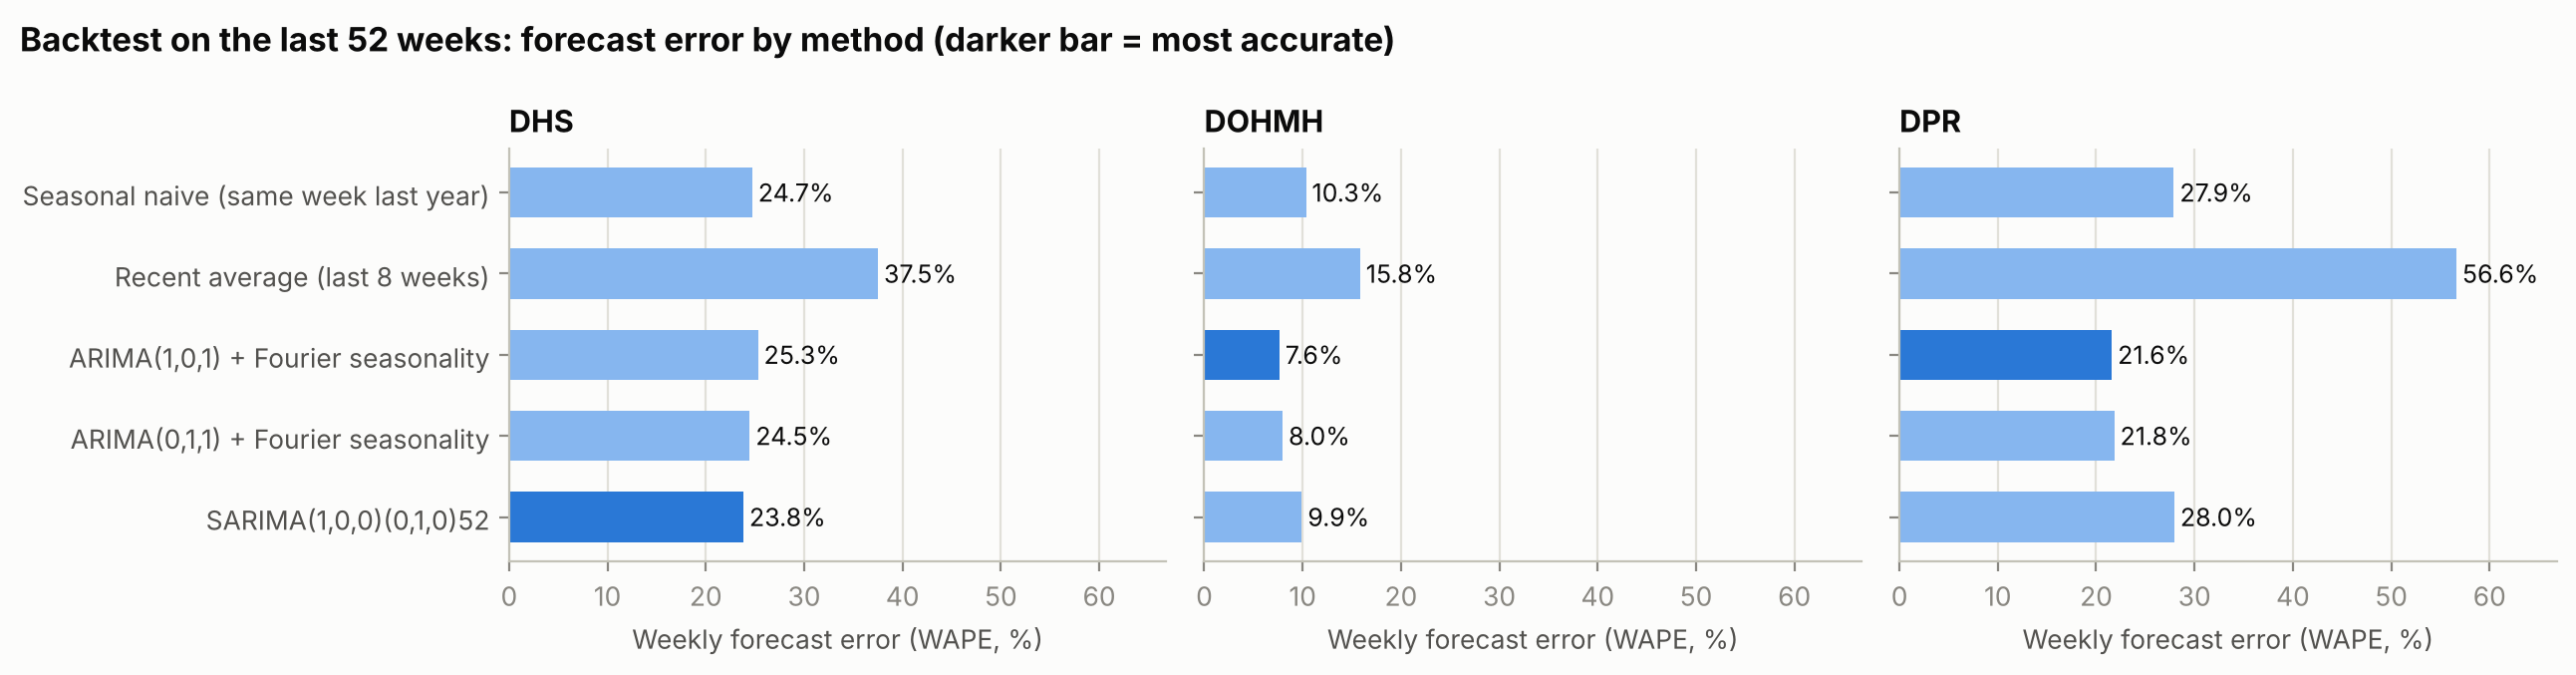

In [6]:
# --- Step 6: chart the backtest ---
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
order = list(MODELS)[::-1]
for ax, a in zip(axes, AGENCIES):
    s = scores[scores['agency'] == a].set_index('model').loc[order]
    bars = ax.barh(range(len(order)), s['WAPE'] * 100, height=0.62,
                   color=[BLUE if b else BLUE_LIGHT for b in s['best']])
    for i, v in enumerate(s['WAPE'] * 100):
        ax.text(v + 0.6, i, f'{v:.1f}%', va='center', color=INK, fontsize=9)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, color='#52514e')
    ax.set_title(a, loc='left'); ax.set_xlabel('Weekly forecast error (WAPE, %)')
    ax.set_xlim(0, scores['WAPE'].max() * 100 * 1.18); ax.grid(axis='y', visible=False)
fig.suptitle('Backtest on the last 52 weeks: forecast error by method (darker bar = most accurate)',
             x=0.01, ha='left', fontsize=12, fontweight='bold', color=INK)
fig.tight_layout(); fig.savefig(f'{IMG_DIR}/ws3_backtest_wape.png', dpi=150); plt.show()

DHS: SARIMA(1,0,0)(0,1,0)52 (interval from backtest errors, because the model interval covered only 64%)
    forecast avg 778/week (80% interval 501 to 1,155), peak week 1,337 on 2026-10-26; last 13 weeks averaged 1,283 (-39%)


DOHMH: ARIMA(1,0,1) + Fourier seasonality (interval from backtest errors, because the model interval covered only 67%, 3 Fourier pair(s))
    forecast avg 1,384/week (80% interval 1,221 to 1,574), peak week 1,565 on 2026-10-26; last 13 weeks averaged 1,903 (-27%)


DPR: ARIMA(1,0,1) + Fourier seasonality (interval from backtest errors, because the model interval covered only 67%, 3 Fourier pair(s))
    forecast avg 1,411/week (80% interval 1,132 to 2,220), peak week 2,433 on 2026-10-26; last 13 weeks averaged 3,470 (-59%)

Forecast window: 2026-10-26 to 2027-01-18 (week starts)


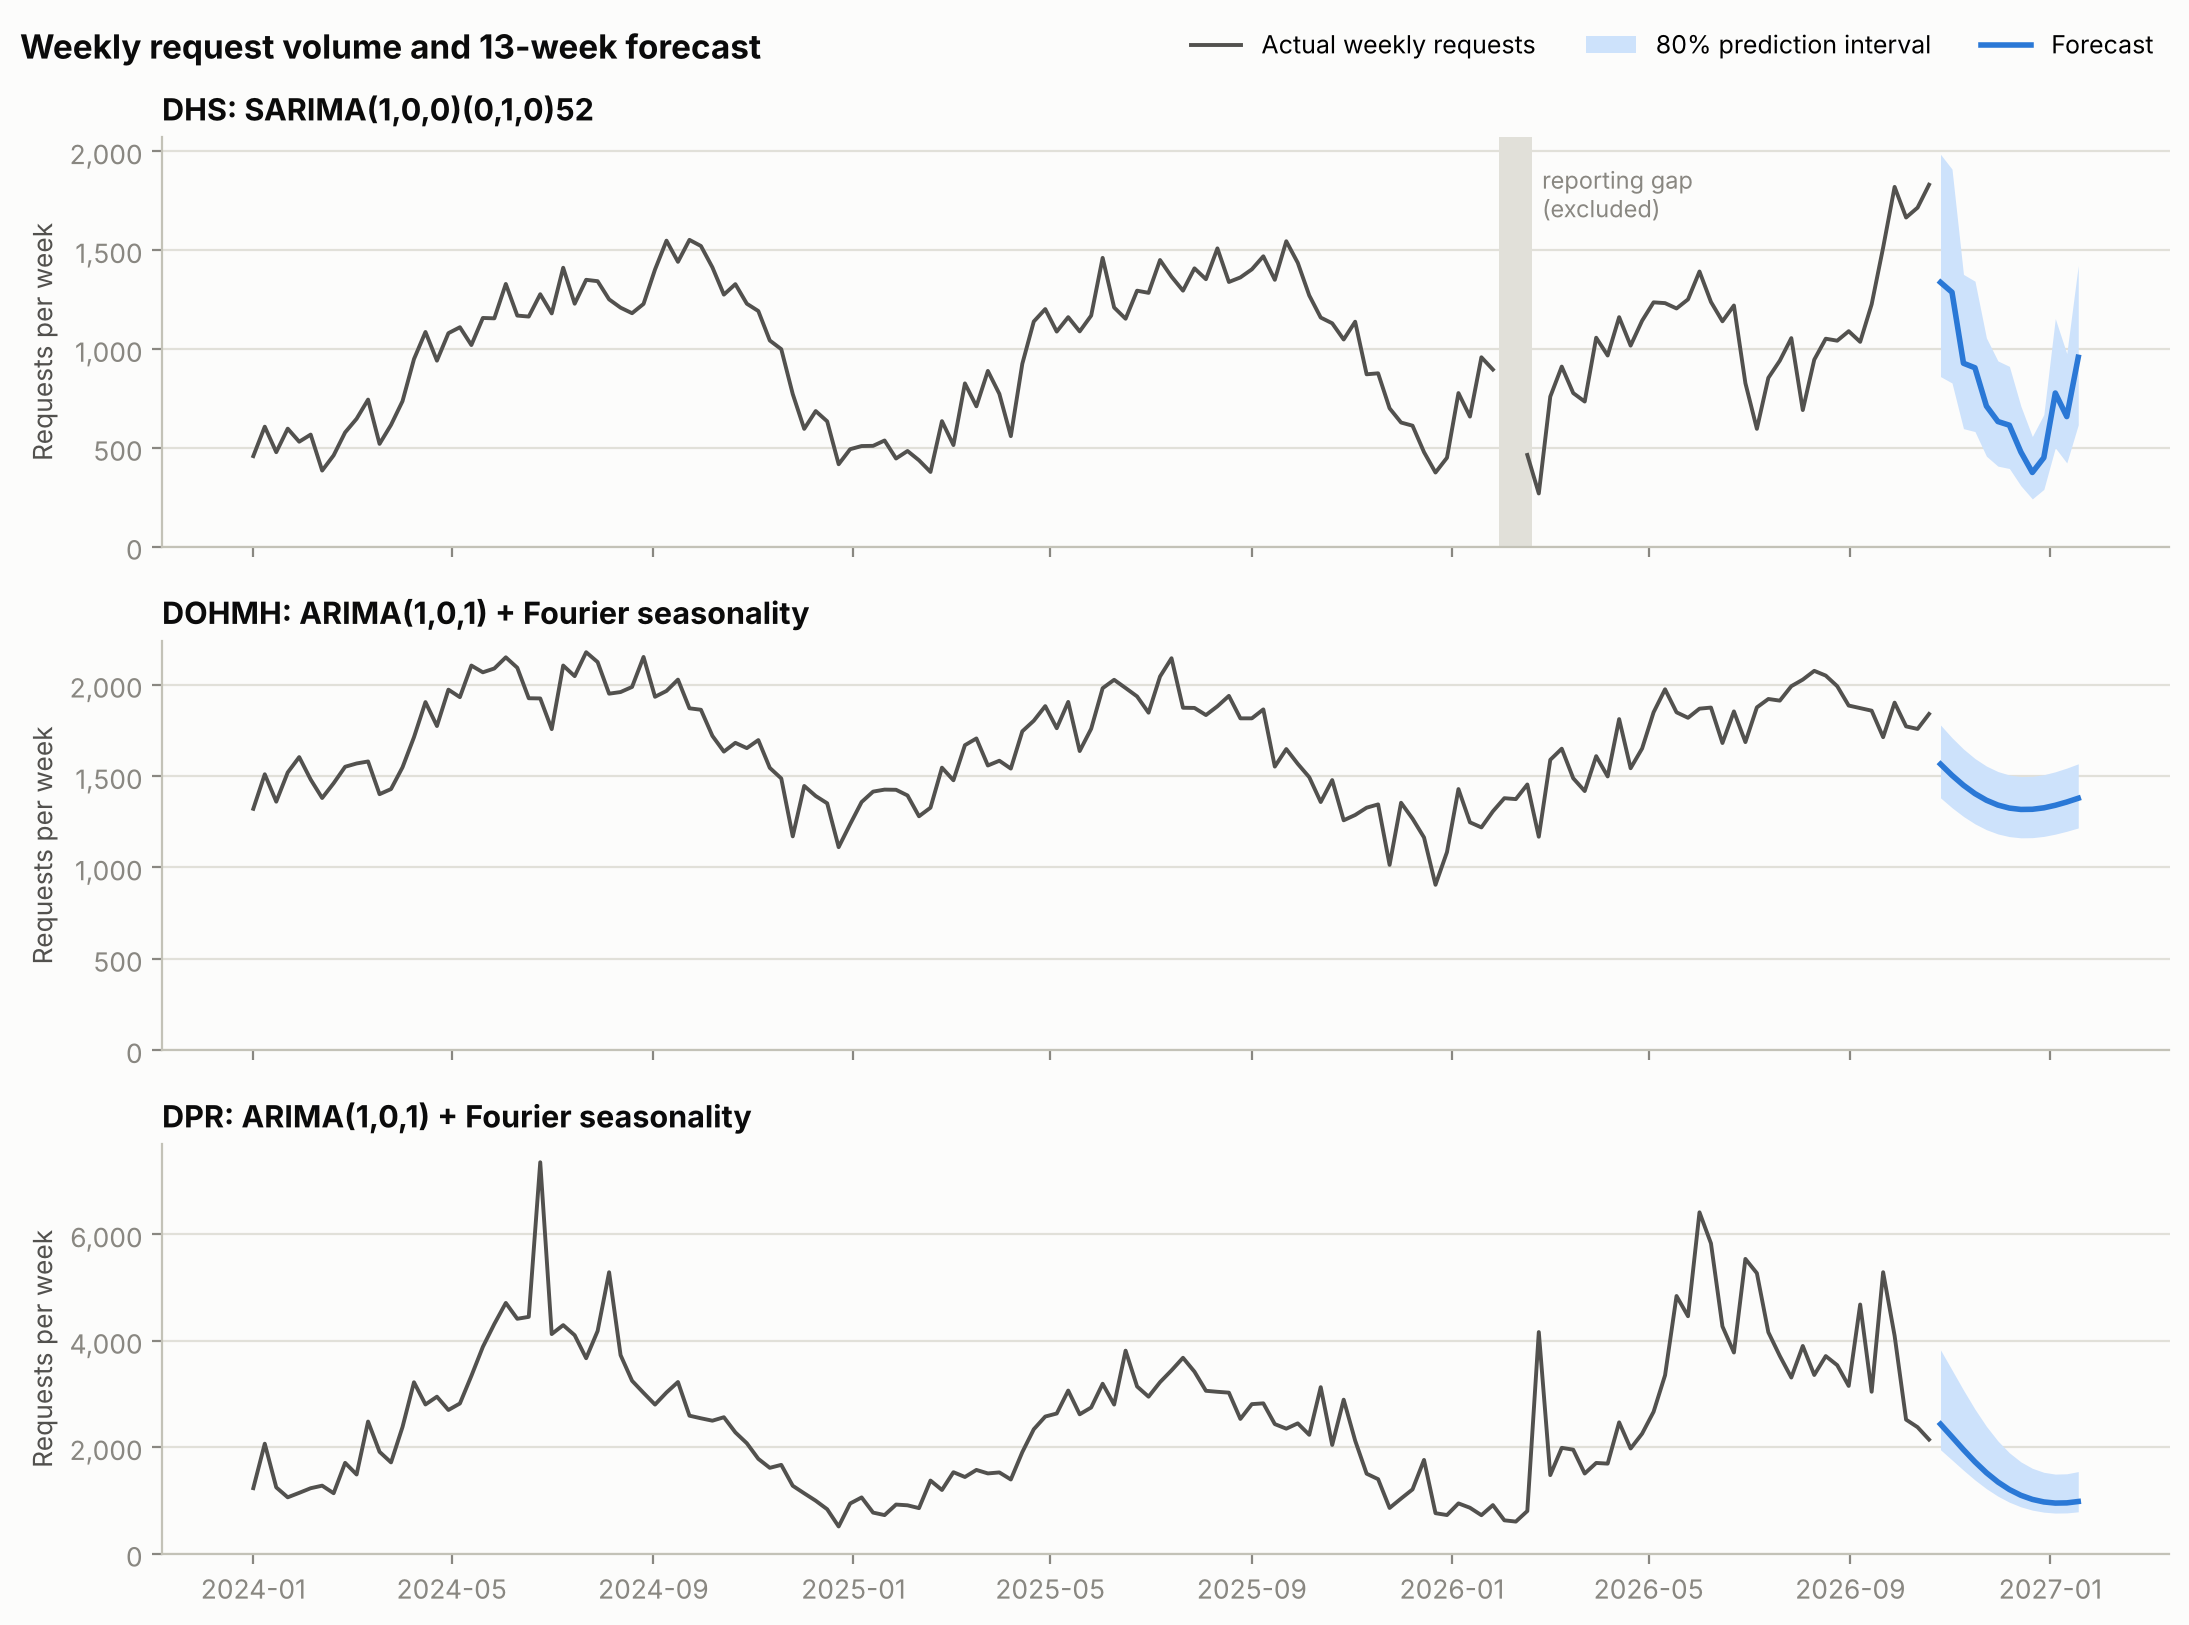

In [7]:
# --- Step 7: forecast the next 13 weeks with each agency's best method ---
fc, interval_note = {}, {}
for a in AGENCIES:
    f = MODELS[winner[a]](weekly[a], HORIZON)
    cov = scores.loc[(scores['agency'] == a) & (scores['model'] == winner[a]), 'coverage_80'].iloc[0]
    if f['lo'].isna().all() or cov < 0.70:
        # No model interval (baselines), or the model interval proved too narrow in the backtest:
        # use the 10th and 90th percentile of this method's own backtest errors instead
        e = bt[(bt['agency'] == a) & (bt['model'] == winner[a])]
        ratio = np.log(e['actual'] / e['fc'])
        f['lo'], f['hi'] = f['fc'] * np.exp(ratio.quantile(0.10)), f['fc'] * np.exp(ratio.quantile(0.90))
        note = 'interval from backtest errors' + ('' if pd.isna(cov) else f', because the model interval covered only {cov:.0%}')
    else:
        note = f'model interval, backtest coverage {cov:.0%}'
    if 'K' in f.attrs:
        note += f", {f.attrs['K']} Fourier pair(s)"
    interval_note[a] = note
    fc[a] = f
    last13 = weekly[a].dropna().tail(13).mean()
    print(f"{a}: {winner[a]} ({note})")
    print(f"    forecast avg {f['fc'].mean():,.0f}/week (80% interval {f['lo'].mean():,.0f} to {f['hi'].mean():,.0f}), "
          f"peak week {f['fc'].max():,.0f} on {f['fc'].idxmax().date()}; last 13 weeks averaged {last13:,.0f} "
          f"({f['fc'].mean() / last13 - 1:+.0%})")

forecast = pd.concat([f.assign(agency=a) for a, f in fc.items()]).rename_axis('week_start').reset_index()
forecast = forecast[['agency', 'week_start', 'fc', 'lo', 'hi']].round(0)
forecast.to_csv(f'{DATA_DIR}/ws3_forecast_weekly.csv', index=False)
print(f'\nForecast window: {forecast.week_start.min().date()} to {forecast.week_start.max().date()} (week starts)')

fig, axes = plt.subplots(3, 1, figsize=(11, 8.2), sharex=True)
for ax, a in zip(axes, AGENCIES):
    y, f = weekly[a], fc[a]
    ax.plot(y.index, y.values, color=HIST, lw=1.4, label='Actual weekly requests')
    ax.fill_between(f.index, f['lo'], f['hi'], color=BLUE_BAND, lw=0, label='80% prediction interval')
    ax.plot(f.index, f['fc'], color=BLUE, lw=2, label='Forecast')
    gaps = y[y.isna()].index
    if len(gaps):
        ax.axvspan(gaps.min() - pd.Timedelta(days=3), gaps.max() + pd.Timedelta(days=10), color=GRID, lw=0)
        ax.text(gaps.max() + pd.Timedelta(days=16), ax.get_ylim()[1] * 0.93, 'reporting gap\n(excluded)', color=MUTED, fontsize=8.5, va='top')
    ax.set_title(f'{a}: {winner[a]}', loc='left'); ax.set_ylabel('Requests per week'); ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}')); ax.grid(axis='x', visible=False)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='upper right', ncol=3, fontsize=9, bbox_to_anchor=(0.99, 0.992))
fig.suptitle('Weekly request volume and 13-week forecast', x=0.01, ha='left', fontsize=12, fontweight='bold', color=INK)
fig.tight_layout(); fig.savefig(f'{IMG_DIR}/ws3_forecast.png', dpi=150); plt.show()

Assumed handle time (hours per request): {'DHS': 1.5, 'DOHMH': 1.0, 'DPR': 2.0} | productive hours per FTE-week: 23.8

agency                            scenario avg_weekly_volume fte_avg_week fte_peak_week vs_base
   DHS              Base (median forecast)               778         49.0          84.3     +0%
   DHS High-demand weeks (upper 80% bound)             1,155         72.8         125.1    +48%
   DHS                  Growth +15% volume               895         56.4          96.9    +15%
   DHS        Efficiency: handle time -15%               778         41.7          71.6    -15%
   DHS  Stress: +15% volume at upper bound             1,328         83.7         143.9    +71%
 DOHMH              Base (median forecast)             1,384         58.2          65.8     +0%
 DOHMH High-demand weeks (upper 80% bound)             1,574         66.1          74.8    +14%
 DOHMH                  Growth +15% volume             1,592         66.9          75.6    +15%
 DOHMH        Eff

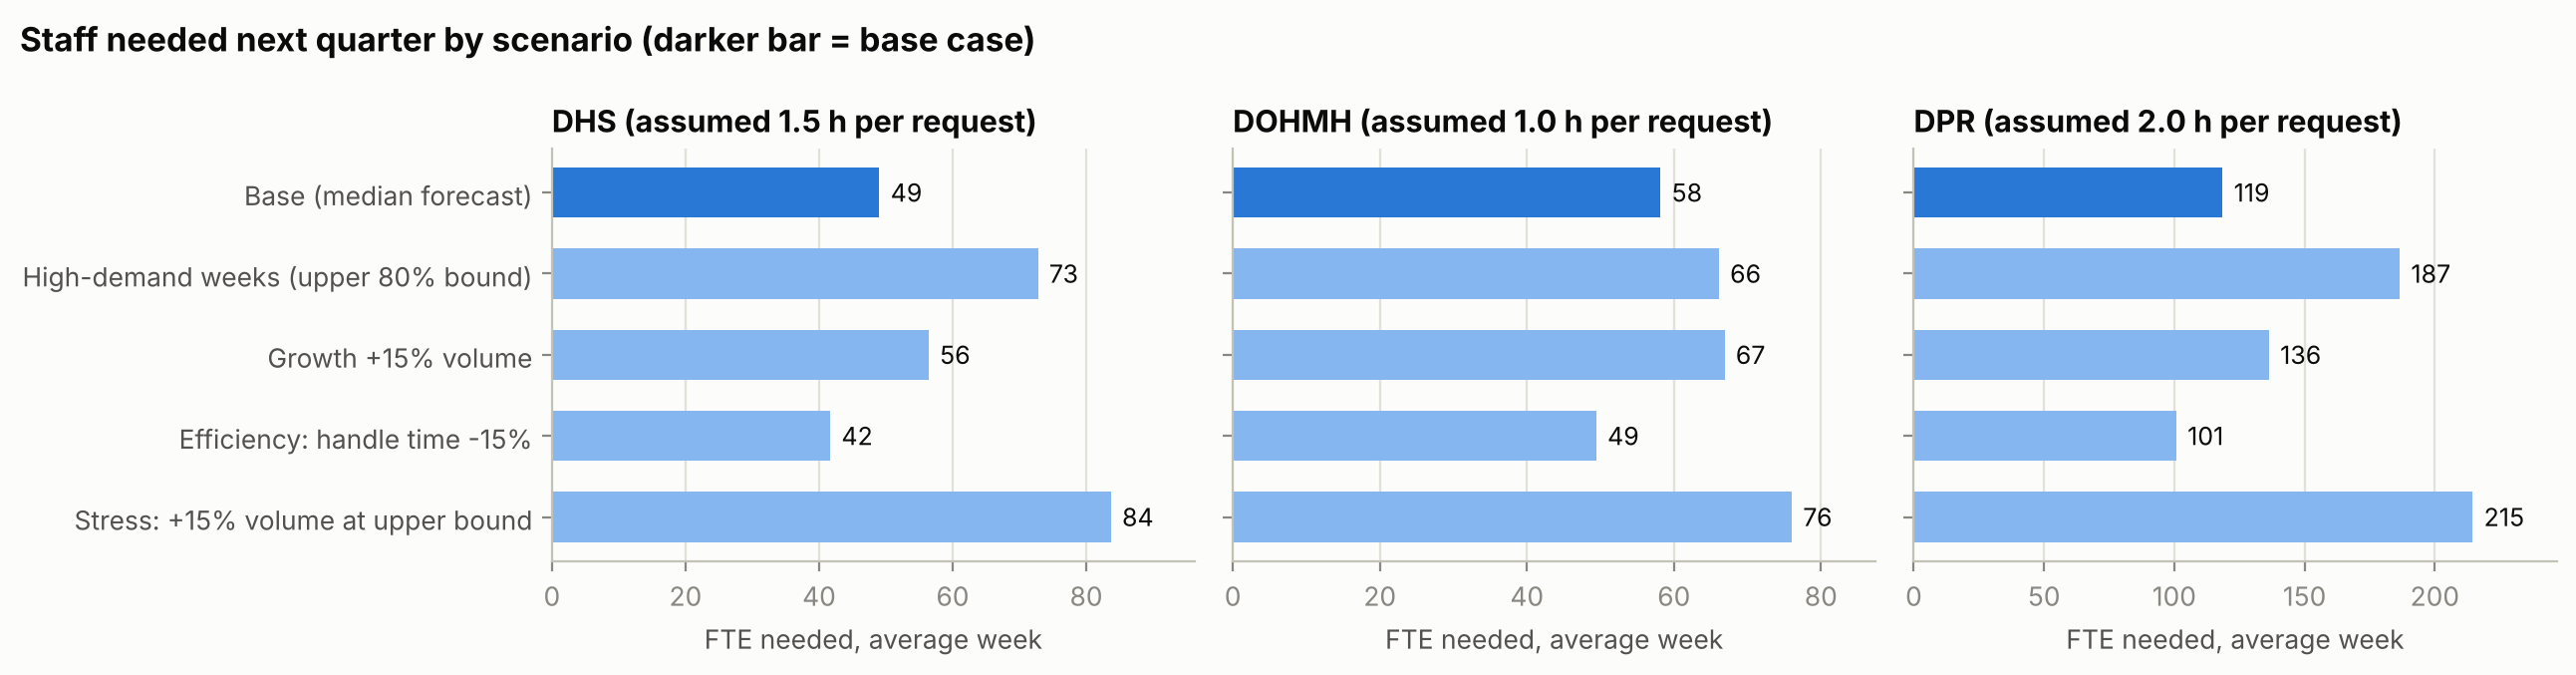

In [8]:
# --- Step 8: staffing scenarios ---
# FTE = weekly volume x handle time / productive hours per FTE.
# Each scenario: which forecast line to staff to, a volume multiplier, and a handle-time multiplier.
SCENARIOS = {
    'Base (median forecast)':               ('fc', 1.00, 1.00),
    'High-demand weeks (upper 80% bound)':  ('hi', 1.00, 1.00),
    'Growth +15% volume':                   ('fc', 1.15, 1.00),
    'Efficiency: handle time -15%':         ('fc', 1.00, 0.85),
    'Stress: +15% volume at upper bound':   ('hi', 1.15, 1.00),
}
rows = []
for a in AGENCIES:
    for name, (line, vol_x, aht_x) in SCENARIOS.items():
        vol = fc[a][line] * vol_x
        fte = vol * ASSUMED_AHT_HOURS[a] * aht_x / PROD_HOURS
        rows.append({'agency': a, 'scenario': name, 'avg_weekly_volume': vol.mean(),
                     'fte_avg_week': fte.mean(), 'fte_peak_week': fte.max()})
staff = pd.DataFrame(rows)
tot = staff.groupby('scenario', sort=False)[['avg_weekly_volume', 'fte_avg_week', 'fte_peak_week']].sum().reset_index().assign(agency='ALL')
staff = pd.concat([staff, tot], ignore_index=True)
base = staff[staff['scenario'] == 'Base (median forecast)'].set_index('agency')['fte_avg_week']
staff['vs_base'] = staff['fte_avg_week'] / staff['agency'].map(base) - 1
staff.round(2).to_csv(f'{DATA_DIR}/ws3_staffing_scenarios.csv', index=False)

print(f'Assumed handle time (hours per request): {ASSUMED_AHT_HOURS} | productive hours per FTE-week: {PROD_HOURS:.1f}\n')
show = staff.copy()
show['avg_weekly_volume'] = show['avg_weekly_volume'].map('{:,.0f}'.format)
show['fte_avg_week'] = show['fte_avg_week'].map('{:,.1f}'.format); show['fte_peak_week'] = show['fte_peak_week'].map('{:,.1f}'.format)
show['vs_base'] = show['vs_base'].map('{:+.0%}'.format)
print(show.to_string(index=False))

# Reference point: what a plan based on the recent run rate (average of the last 13 weeks) would staff
run_rate = pd.DataFrame({'last13_avg_volume': {a: weekly[a].dropna().tail(13).mean() for a in AGENCIES}})
run_rate['fte_at_run_rate'] = run_rate['last13_avg_volume'] * pd.Series(ASSUMED_AHT_HOURS) / PROD_HOURS
run_rate['fte_base_forecast'] = base[AGENCIES]
run_rate.loc['ALL'] = run_rate.sum()
run_rate['forecast_vs_run_rate'] = run_rate['fte_base_forecast'] / run_rate['fte_at_run_rate'] - 1
print('\nStaffing from the last 13 weeks\' run rate vs from the forecast (average week):')
print(run_rate.round({'last13_avg_volume': 0, 'fte_at_run_rate': 1, 'fte_base_forecast': 1, 'forecast_vs_run_rate': 3}).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
names = list(SCENARIOS)[::-1]
for ax, a in zip(axes, AGENCIES):
    s = staff[staff['agency'] == a].set_index('scenario').loc[names]
    ax.barh(range(len(names)), s['fte_avg_week'], height=0.62,
            color=[BLUE if n.startswith('Base') else BLUE_LIGHT for n in names])
    for i, v in enumerate(s['fte_avg_week']):
        ax.text(v + s['fte_avg_week'].max() * 0.02, i, f'{v:,.0f}', va='center', color=INK, fontsize=9)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, color='#52514e')
    ax.set_title(f'{a} (assumed {ASSUMED_AHT_HOURS[a]} h per request)', loc='left'); ax.set_xlabel('FTE needed, average week')
    ax.set_xlim(0, s['fte_avg_week'].max() * 1.15); ax.grid(axis='y', visible=False)
fig.suptitle('Staff needed next quarter by scenario (darker bar = base case)', x=0.01, ha='left', fontsize=12, fontweight='bold', color=INK)
fig.tight_layout(); fig.savefig(f'{IMG_DIR}/ws3_staffing_scenarios.png', dpi=150); plt.show()

**Reading the scenarios**
- **Base** staffs to the middle of the forecast: about half of weeks will run above it.
- **High-demand weeks** staffs to each week's upper 80% bound, so roughly nine weeks in ten are covered. The gap between this and Base is the price of a buffer.
- The **ALL** row adds the three agencies. For the upper-bound scenarios that overstates a pooled team's need, because the agencies rarely peak in the same week.

In [9]:
# --- Step 9: what if growth arrives and headcount stays at the base plan? ---
# Headcount is fixed at the base plan, rounded up. Requests beyond weekly capacity carry over to the next week.
def simulate_queue(demand, capacity):
    q, path = 0.0, []
    for dmd in demand:
        q = max(0.0, q + dmd - capacity); path.append(q)
    return np.array(path)

rows = []
for a in AGENCIES:
    heads = math.ceil(base[a])
    capacity = heads * PROD_HOURS / ASSUMED_AHT_HOURS[a]                 # requests the team can work per week
    for label, mult in [('Base demand', 1.00), ('Growth +15%', 1.15)]:
        demand = fc[a]['fc'].values * mult
        q = simulate_queue(demand, capacity)
        rows.append({'agency': a, 'headcount': heads, 'weekly_capacity': round(capacity), 'demand': label,
                     'weeks_over_capacity': int((demand > capacity).sum()), 'peak_carryover': round(q.max()),
                     'carryover_at_week_13': round(q[-1]), 'weeks_of_work_behind': round(q[-1] / capacity, 1)})
queue = pd.DataFrame(rows)
print(queue.to_string(index=False))

# Sensitivity: total FTE (all agencies, average week) as volume growth and handle time move together
grid = pd.DataFrame({f'AHT {h:+.0%}': {f'volume {g:+.0%}': base[AGENCIES].sum() * (1 + g) * (1 + h) for g in (0, 0.10, 0.20, 0.30)}
                     for h in (-0.20, -0.10, 0, 0.10, 0.20)})
print('\nTotal FTE, average week (all three agencies):')
print(grid.round(0).astype(int).to_string())

agency  headcount  weekly_capacity      demand  weeks_over_capacity  peak_carryover  carryover_at_week_13  weeks_of_work_behind
   DHS         50              793 Base demand                    5            1283                   165                   0.2
   DHS         50              793 Growth +15%                    7            1976                  1317                   1.7
 DOHMH         59             1404 Base demand                    3             307                     0                   0.0
 DOHMH         59             1404 Growth +15%                   13            2441                  2441                   1.7
   DPR        119             1416 Base demand                    5            2745                     0                   0.0
   DPR        119             1416 Growth +15%                    6            4350                  2687                   1.9

Total FTE, average week (all three agencies):
             AHT -20%  AHT -10%  AHT +0%  AHT +10%  AHT +

In [10]:
# --- Step 10: results block for the README (copy everything this cell prints) ---
print('=== WORKSTREAM 3 RESULTS ===')
print(f'source: {source} | total requests: {total:,} | complete weeks: {len(weekly)} ({weekly.index[0].date()} to {weekly.index[-1].date()})')
print(f"gap weeks set to missing: { {a: len(w) for a, w in KNOWN_GAPS.items()} }")
print(f'forecast window (week starts): {forecast.week_start.min().date()} to {forecast.week_start.max().date()}')
print(f'assumptions: AHT hours {ASSUMED_AHT_HOURS}, paid {PAID_HOURS}, shrinkage {SHRINKAGE}, occupancy {OCCUPANCY}, productive {PROD_HOURS:.1f}')
print('\n-- backtest --')
print(scores.round(4).to_string(index=False))
print('\n-- forecast --')
for a in AGENCIES:
    f = fc[a]
    print(f"{a}: method={winner[a]} | {interval_note[a]} | avg={f['fc'].mean():.0f} lo={f['lo'].mean():.0f} hi={f['hi'].mean():.0f} | "
          f"peak={f['fc'].max():.0f} on {f['fc'].idxmax().date()} | last13_avg={weekly[a].dropna().tail(13).mean():.0f} | "
          f"same13_last_year_avg={weekly[a].interpolate().reindex(f.index - pd.Timedelta(weeks=52)).mean():.0f}")
print('\n-- staffing --')
print(staff.round(2).to_string(index=False))
print('\n-- run rate vs forecast --')
print(run_rate.round(3).to_string())
print('\n-- fixed headcount --')
print(queue.to_string(index=False))
print('\n-- sensitivity --')
print(grid.round(1).to_string())

=== WORKSTREAM 3 RESULTS ===
source: cached CSV | total requests: 773,169 | complete weeks: 147 (2024-01-01 to 2026-10-19)
gap weeks set to missing: {'DHS': 2}
forecast window (week starts): 2026-10-26 to 2027-01-18
assumptions: AHT hours {'DHS': 1.5, 'DOHMH': 1.0, 'DPR': 2.0}, paid 40, shrinkage 0.3, occupancy 0.85, productive 23.8

-- backtest --
agency                                model   WAPE    bias  quarter_error  coverage_80  best
   DHS   ARIMA(0,1,1) + Fourier seasonality 0.2447 -0.0893         0.1446       0.5400 False
   DHS   ARIMA(1,0,1) + Fourier seasonality 0.2530  0.0273         0.0952       0.5000 False
   DHS        Recent average (last 8 weeks) 0.3751  0.0015         0.3586          NaN False
   DHS               SARIMA(1,0,0)(0,1,0)52 0.2382  0.0322         0.0759       0.6400  True
   DHS Seasonal naive (same week last year) 0.2472  0.0369         0.0849          NaN False
 DOHMH   ARIMA(0,1,1) + Fourier seasonality 0.0797 -0.0358         0.0594       0.6538 Fals